In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = np.load(
    "./sampling_experiment_results/computers_sampling_full.npz"
)

P = data["probabilities"]

print("Shape:", P.shape)
print("K values:", data["k_values"])
print("Repeats:", data["repeats"])
print("Number of nodes:", len(data["node_ids"]))

print("Any NaNs:", np.isnan(P).any())
print("Any infinities:", np.isinf(P).any())

# Every probability vector should sum to approximately 1
sums = P.sum(axis=-1)

print(
    "Probability-sum range:",
    sums.min(),
    sums.max()
)

Shape: (6, 50, 2751, 10)
K values: [  4   8  16  32  64 128]
Repeats: 50
Number of nodes: 2751
Any NaNs: False
Any infinities: False
Probability-sum range: 0.9999997 1.0000002


In [2]:
for k_idx, K in enumerate(data["k_values"]):

    mean_abs_change = np.mean(
        np.abs(
            P[k_idx, 0] -
            P[k_idx, 1]
        )
    )

    print(
        f"K={K}: "
        f"mean |repeat 1 - repeat 2| "
        f"= {mean_abs_change:.8f}"
    )

K=4: mean |repeat 1 - repeat 2| = 0.02924143
K=8: mean |repeat 1 - repeat 2| = 0.02006023
K=16: mean |repeat 1 - repeat 2| = 0.01252471
K=32: mean |repeat 1 - repeat 2| = 0.00941943
K=64: mean |repeat 1 - repeat 2| = 0.00603567
K=128: mean |repeat 1 - repeat 2| = 0.00440408


In [17]:
def entropy(p):
    p = np.clip(p, 1e-12, 1.0)
    return -np.sum(p * np.log(p), axis=-1)

In [18]:
P = data["probabilities"]
labels = data["labels"].astype(int)
node_ids = data["node_ids"]
k_values = data["k_values"].astype(int)

n_k, R, N, C = P.shape

print("Probability tensor:", P.shape)
print("K values:", k_values)
print("Repeats:", R)
print("Test nodes:", N)
print("Classes:", C)

Probability tensor: (6, 50, 2751, 10)
K values: [  4   8  16  32  64 128]
Repeats: 50
Test nodes: 2751
Classes: 10


In [19]:
mean_p = P.mean(axis=1)

predictive_entropy = entropy(mean_p)

individual_entropy = entropy(P)

mean_conditional_entropy = individual_entropy.mean(axis=1)

u_sampling = predictive_entropy - mean_conditional_entropy
u_sampling = np.maximum(u_sampling, 0.0)

In [20]:
print("mean_p: ", mean_p)
print("predictive_entropy: ", predictive_entropy)
print("individual_entropy: ", individual_entropy)
print("mean_conditional_entropy: ", mean_conditional_entropy)
print("u_sampling: ", u_sampling)

mean_p:  [[[0.02615277 0.10051274 0.00616191 ... 0.00556209 0.19287008 0.00560773]
  [0.01354382 0.5060786  0.02211019 ... 0.30171618 0.03498014 0.01392687]
  [0.00684473 0.01565113 0.00474441 ... 0.00485394 0.04703995 0.00288471]
  ...
  [0.00170458 0.02773409 0.00632731 ... 0.9414308  0.00152499 0.00280391]
  [0.00754214 0.0012242  0.00407168 ... 0.00869837 0.05387346 0.0035477 ]
  [0.00309005 0.00844233 0.00442044 ... 0.00346424 0.01340747 0.00476585]]

 [[0.02044586 0.12116275 0.00620739 ... 0.00544268 0.14225328 0.00612424]
  [0.01396848 0.4825486  0.00989874 ... 0.32314095 0.03398523 0.01575727]
  [0.00523385 0.00994682 0.00395256 ... 0.00468156 0.01887528 0.00241694]
  ...
  [0.00147416 0.02142856 0.00536614 ... 0.95138246 0.00122437 0.00251419]
  [0.00722919 0.00112677 0.00386935 ... 0.00852376 0.03991257 0.00335776]
  [0.00272603 0.00424511 0.003903   ... 0.00298057 0.00762725 0.00394512]]

 [[0.01782784 0.08545989 0.00636363 ... 0.00544009 0.12918764 0.00577962]
  [0.01356849

In [21]:
max_entropy =  np.log(C)

predictive_entropy_norm = predictive_entropy / max_entropy
u_sampling_norm = u_sampling / max_entropy

predictions = P.argmax(axis=-1)

disagreement = np.zeros((n_k, N))

unique_prediction_count = np.zeros((n_k, N), dtype=int)

In [22]:
for ki in range(n_k):
    for i in range(N):

        counts = np.bincount(
            predictions[ki, :, i],
            minlength=C,
        )

        disagreement[ki, i] = (
            1.0 - counts.max() / R
        )

        unique_prediction_count[ki, i] = (
            np.count_nonzero(counts)
        )

In [23]:
accuracy_per_repeat = (predictions == labels[None, None, :]).mean(axis=-1)

In [24]:
mean_prediction = mean_p.argmax(axis=-1)

ensemble_accuracy = ( mean_prediction == labels[None, :]).mean(axis=-1)

In [25]:
true_class_probability = np.take_along_axis(
        P,
        labels[None, None, :, None],
        axis=-1,
    ).squeeze(-1)

    # Five-number summary for EACH node
true_min = np.min(
    true_class_probability,
    axis=1,
)

true_q1 = np.quantile(
    true_class_probability,
    0.25,
    axis=1,
)

true_median = np.median(
    true_class_probability,
    axis=1,
)

true_q3 = np.quantile(
    true_class_probability,
    0.75,
    axis=1,
)

true_max = np.max(
    true_class_probability,
    axis=1,
)

true_std = np.std(
    true_class_probability,
    axis=1,
)

In [26]:
rows = []

for ki, K in enumerate(k_values):
    for i in range(N):
        rows.append(
            {
                "K": K,
                "node_id": int(node_ids[i]),
                "true_label": int(labels[i]),

                "predictive_entropy":
                    predictive_entropy[ki, i],

                "predictive_entropy_norm":
                    predictive_entropy_norm[ki, i],

                "mean_conditional_entropy":
                    mean_conditional_entropy[ki, i],

                "u_sampling":
                    u_sampling[ki, i],

                "u_sampling_norm":
                    u_sampling_norm[ki, i],

                "disagreement":
                    disagreement[ki, i],

                "unique_predicted_classes":
                    unique_prediction_count[ki, i],

                "mean_prediction":
                    int(mean_prediction[ki, i]),

                "correct":
                    int(
                        mean_prediction[ki, i]
                        == labels[i]
                    ),

                "true_prob_min":
                    true_min[ki, i],

                "true_prob_q1":
                    true_q1[ki, i],

                "true_prob_median":
                    true_median[ki, i],

                "true_prob_q3":
                    true_q3[ki, i],

                "true_prob_max":
                    true_max[ki, i],

                "true_prob_std":
                    true_std[ki, i],
            }
        )

In [27]:
summary_rows = []

for ki, K in enumerate(k_values):

        U = u_sampling[ki]
        H = predictive_entropy[ki]
        D = disagreement[ki]

        summary_rows.append(
            {
                "K": K,

                "accuracy_mean":
                    accuracy_per_repeat[ki].mean(),

                "accuracy_std":
                    accuracy_per_repeat[ki].std(),

                "ensemble_accuracy":
                    ensemble_accuracy[ki],

                "u_sampling_mean":
                    U.mean(),

                "u_sampling_std":
                    U.std(),

                "u_sampling_min":
                    U.min(),

                "u_sampling_q1":
                    np.quantile(U, 0.25),

                "u_sampling_median":
                    np.median(U),

                "u_sampling_q3":
                    np.quantile(U, 0.75),

                "u_sampling_max":
                    U.max(),

                "predictive_entropy_mean":
                    H.mean(),

                "conditional_entropy_mean":
                    mean_conditional_entropy[ki].mean(),

                "disagreement_mean":
                    D.mean(),

                "fraction_any_disagreement":
                    np.mean(D > 0),

                "mean_unique_classes":
                    unique_prediction_count[ki].mean(),
            }
        )

In [28]:
summary = pd.DataFrame(summary_rows)

print("\n========== SUMMARY ==========")
print(summary.to_string(index=False))
print("=============================\n")


========== SUMMARY ==========
  K  accuracy_mean  accuracy_std  ensemble_accuracy  u_sampling_mean  u_sampling_std  u_sampling_min  u_sampling_q1  u_sampling_median  u_sampling_q3  u_sampling_max  predictive_entropy_mean  conditional_entropy_mean  disagreement_mean  fraction_any_disagreement  mean_unique_classes
  4       0.857717      0.004888           0.907670         0.122523        0.144307             0.0       0.014039           0.064417       0.190621        0.798079                 0.605930                  0.483407           0.087823                   0.521628             1.977826
  8       0.883759      0.003725           0.906943         0.059287        0.089036             0.0       0.003690           0.015666       0.079391        0.598486                 0.505511                  0.446224           0.055187                   0.328244             1.482007
 16       0.897266      0.002922           0.909851         0.029561        0.052989             0.0       0.001363  

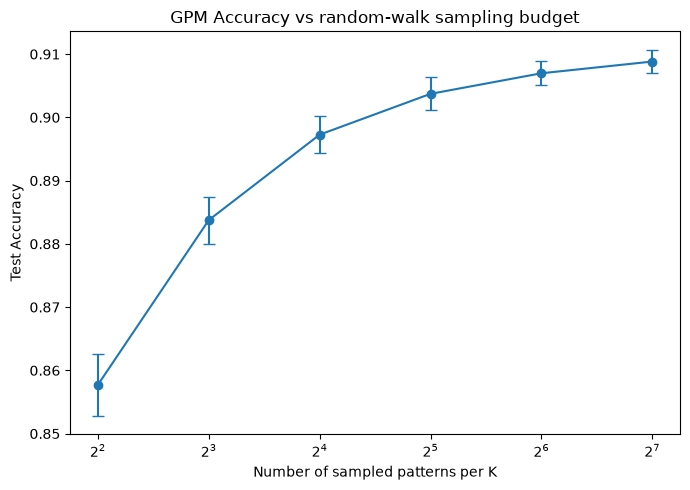

In [31]:
# plot 1: accuracy vs K
plt.figure(figsize=(7, 5))

plt.errorbar(
    k_values,
    accuracy_per_repeat.mean(axis=1),
    yerr=accuracy_per_repeat.std(axis=1),
    marker="o",
    capsize=4
)

plt.xscale("log", base=2)

plt.xlabel("Number of sampled patterns per K")
plt.ylabel("Test Accuracy")
plt.title("GPM Accuracy vs random-walk sampling budget")

plt.tight_layout()

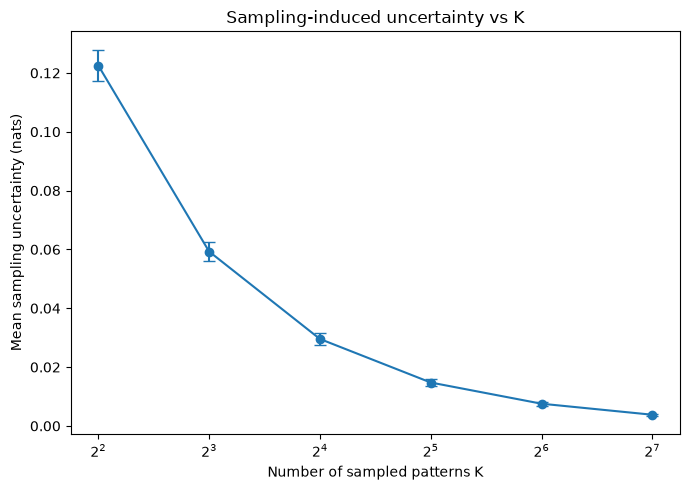

In [32]:
# plot 2: mean u_sampling vs k

plt.figure(figsize=(7, 5))

means = u_sampling.mean(axis=1)

sem = (
    u_sampling.std(axis=1)
    / np.sqrt(N)
)

plt.errorbar(
    k_values,
    means,
    yerr=1.96 * sem,
    marker="o",
    capsize=4,
)

plt.xscale("log", base=2)

plt.xlabel("Number of sampled patterns K")
plt.ylabel("Mean sampling uncertainty (nats)")
plt.title("Sampling-induced uncertainty vs K")

plt.tight_layout()

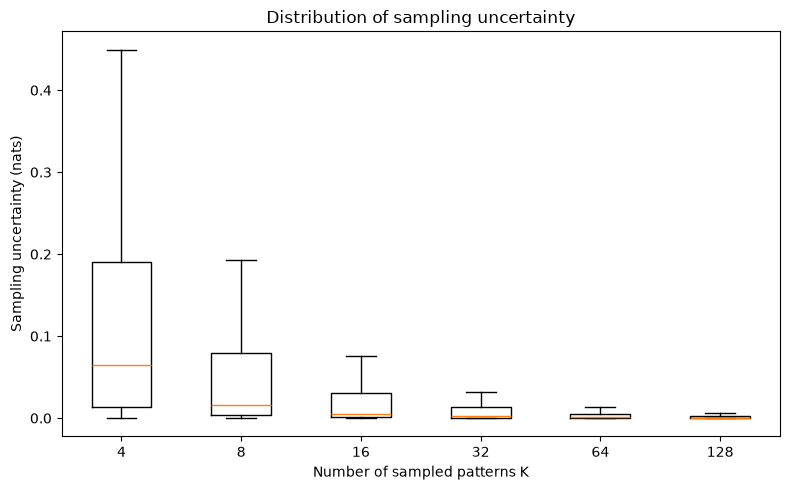

In [34]:
# plot 3: distribution of u_sampling

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        u_sampling[ki]
        for ki in range(n_k)
    ],
    tick_labels=[
        str(K)
        for K in k_values
    ],
    showfliers=False,
)

plt.xlabel("Number of sampled patterns K")
plt.ylabel("Sampling uncertainty (nats)")
plt.title("Distribution of sampling uncertainty")

plt.tight_layout()

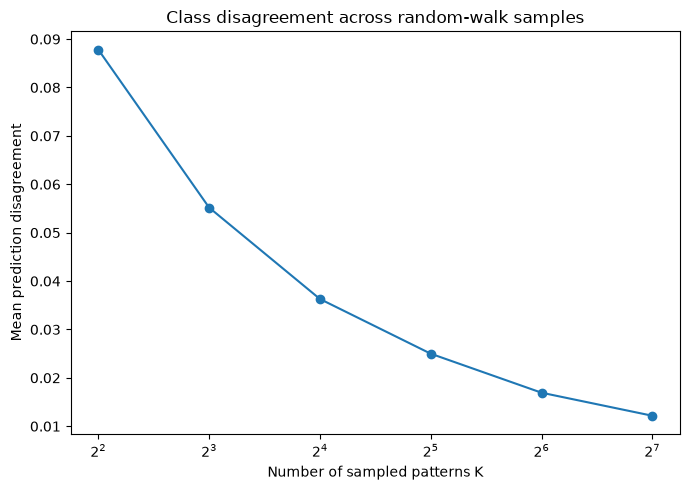

In [35]:
# plot 4: prediction disagreement

plt.figure(figsize=(7, 5))

plt.plot(
    k_values,
    disagreement.mean(axis=1),
    marker="o",
)

plt.xscale("log", base=2)

plt.xlabel("Number of sampled patterns K")
plt.ylabel("Mean prediction disagreement")
plt.title("Class disagreement across random-walk samples")

plt.tight_layout()

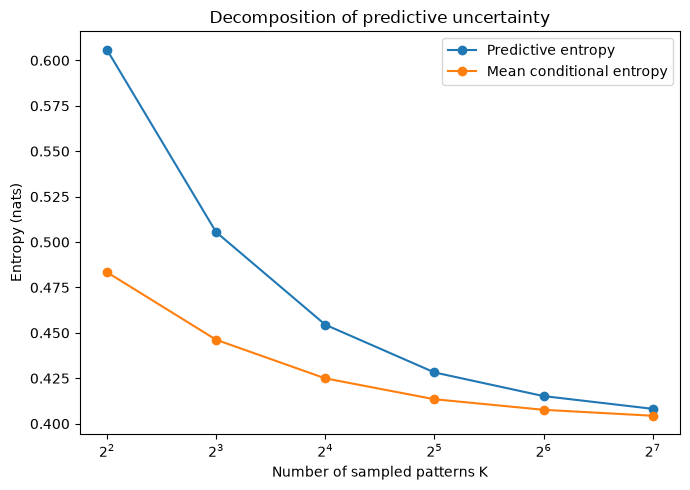

In [37]:
# plot 5: predictive vs conditional entropy

plt.figure(figsize=(7, 5))

plt.plot(
        k_values,
        predictive_entropy.mean(axis=1),
        marker="o",
        label="Predictive entropy",
    )

plt.plot(
        k_values,
        mean_conditional_entropy.mean(axis=1),
        marker="o",
        label="Mean conditional entropy",
    )

plt.xscale("log", base=2)

plt.xlabel("Number of sampled patterns K")
plt.ylabel("Entropy (nats)")
plt.title("Decomposition of predictive uncertainty")
plt.legend()

plt.tight_layout()